# Simulation: Source Spike with Propagation

Explain simulation please

## 📦 Imports

In [1]:
import mindmap as mm

## 🧠 Data


📥 **<font color=pink>Inputs</font>**
- `eeg`: EEG template
- `fwd`: Forward solution
- `sc`: Structural connectome
- `parc`: Parcellation
- `cras`: Transformation (MRI -> RAS)
- `white`: Inner cortical surface
- `hmodel`: Head conductor model 
- `cst`: Connectome spectrum transform
- `ctx`: Cortical mask

🛠️ **<font color=violet>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id (position in list SUBS)

In [2]:
############### Parameters #################
fconfig = "../../papers/simf/configuration.yml"
sub     = 0
############################################

# configuration
reader = mm.io.dataset_reader(fconfig)

# data
data = reader(sub, "eeg", "fwd", "sc", "parc", "cras", "white", "bem", "cst", "ctx")

Coregistered EEG found
DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- cras
- eeg
- bem
- cst
- fwd
- sc
- white
- ctx
- parc
Missing objects:


## Simulation

#### ⚙️ **<font color=green>Generate simulation</font>**
🛠️ **<font color=violet>Source Spike</font>**:
- `duration`: duration of the simulation
- `width`: duration of the spike
- `location`: location of the source spike given by a brain region

🛠️ **<font color=violet>Spike Propagation</font>**:
- `conductance`: Propagation weight [0-1]
- `delay`: Propagation delay in [ms]

🛠️ **<font color=violet>Noise Generation</font>**:
- `target_snr`: Maximum EEG SNR in [dB] expcted
- `noise_ratio`: Ratio [0-1] between brain noise and EEG electrical noise.

In [3]:

########################### Parameters #############################
# Source Spike
duration  = 1000
width     = 100
location  = "random"

# Spike Propagation
conduction      = 0.25
conductance_std = 0  
delay           = 30
delay_std       = 0

# Noise Generation
target_snr  = 15
noise_ratio = 0.9
######################################################################

sim = mm.utils.Simulation(data["fwd"], data["sc"], info=data["eeg"].info, duration=duration, parcellation=data["parc"], cras=data["cras"])
sim.set_spike_attr(width=width, onset=500)
sim.set_prop_attr(conduction=conduction, delay=delay)
sim.set_noise_attr(snr=target_snr, noise_ratio=noise_ratio)
sim.run()

sim.summary()

AttributeError: 'NoneType' object has no attribute 'copy'

#### 🌟 Visualize Simulation

🛠️ **<font color=violet>Simulation plots</font>**:
- `plot`: Plot type. Can be one of ["spike", "brain", "eeg", "noise"]

<font color=red>A good range for EEG electrodes is 10 to 200 uV</font>

Half rising phase:  0.544
Peak phase:  0.56


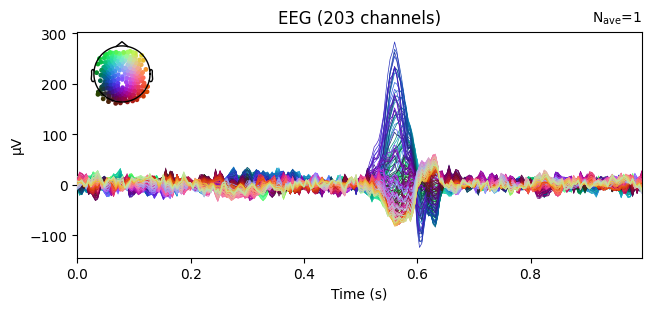

In [ ]:
########################### Parameters #############################
# choose plot ("spike", "brain", "eeg", "noise")
plot = "eeg"
####################################################################

half_phase = mm.utils.eeg_rising_phase(sim.eeg, 0.5)
peak_phase = mm.utils.eeg_rising_phase(sim.eeg, 1)
print("Half rising phase: ", half_phase)
print("Peak phase: ", peak_phase)


if plot == "spike":
    _ = sim.plot_spike(noise=True)
elif plot == "brain":
    sim.plot_brain(noise=True).show()
elif plot == "eeg":
    sim.plot_eeg(noise=True)
elif plot == "noise":
    sim.plot_noise()
else:
    raise ValueError("Unknown plot type")


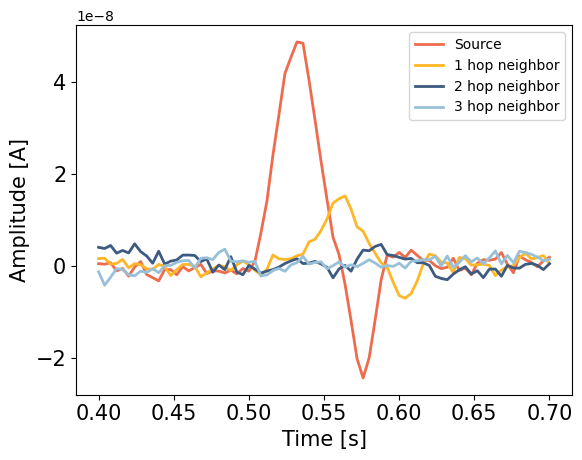

In [ ]:
import matplotlib.pyplot as plt 

brain     = sim.get_activity(noise=True).copy()
brain     = brain.crop(0.4, 0.7)
neighbors = sim.visit

# plot 1 source, 1 1hop neighbor and 1 2hop neighbor
sources = brain.data[neighbors[0]]
hop1    = brain.data[neighbors[1]]
hop2    = brain.data[neighbors[2]]
hop3    = brain.data[neighbors[3]]

times = brain.times

plt.Figure()
plt.plot(times, sources[0], color="#EE6C4D", linewidth=2)
plt.plot(times, hop1[0], color="#FFB627", linewidth=2)
plt.plot(times, hop2[0], color="#3D5A80", linewidth=2)
plt.plot(times, hop3[0], color="#98C1D9", linewidth=2)

plt.xlabel("Time [s]", fontsize=15)
plt.ylabel("Amplitude [A]", fontsize=15)
plt.tick_params(labelsize=15)
plt.legend(["Source", "1 hop neighbor", "2 hop neighbor", "3 hop neighbor"])

In [110]:
import numpy as np
import networkx as nx 
import heapq
from scipy.sparse import csr_matrix, lil_matrix
from collections import defaultdict

def build_delay_weight_matrices(W, D, max_delay):
    N = W.shape[0]
    delay_weights = defaultdict(lambda: lil_matrix((N, N)))

    rows, cols = W.nonzero()
    for i, j in zip(rows, cols):
        delay = int(D[i,j])
        if delay <= max_delay:
            delay_weights[delay][i, j] = W[i, j]

    for d in delay_weights:
        delay_weights[d] = delay_weights[d].tocsr()

    return delay_weights

def propagate_time_series(W, D, source_node, source_series, T, leak):
    """
    Propagate time series over a graph with weighted and delayed edges.

    Parameters:
    ----------
    - W: np.ndarray (N x N)
        Weight matrix.
    - D: np.ndarray (N x N)
        Delay matrix
    - source_node: int
        Index of the node with the initial time series
    - source_series: np.ndarray (T,)
        The known time series at the source node
    - T: int
        Total number of time steps
    - leak factor [0,1]

    Returns:
    - X: np.ndarray (N x T)
        Time series at each node
    """
    N = W.shape[0]
    assert W.shape == D.shape
    assert len(source_series) == T

    # Initialize time series matrix 
    X = np.zeros((N,T))
    X[source_node, :] = source_series

    # Find the maximum delay to precompute delay-weight matrices
    max_delay = min(np.max(D), T) 

    # Precompute delay-specific weight matrices
    if not isinstance(W, csr_matrix):
        W = csr_matrix(W)
    delay_weights = build_delay_weight_matrices(W, D, max_delay)

    # Time propagation
    for t in range(1,T):
        input_sum = np.zeros(N)
        for d, Wd in delay_weights.items():
            if t - d >= 0:
                input_sum += Wd.dot(X[:, t-d])

        # Leaky integration
        X[:, t] = (1- leak) * input_sum + leak * X[:, t-1]

        # Optional: clamp or skip source node if it's fixed
        X[source_node, t] = source_series[t]

    return X


In [126]:
conduction_speed = 0.5                      # ideally myelinated: 150 mm/ms and unmyelinated 0.5-10 mm/ms
synaptic_delay   = 1                        # ideally 0.3-1.0 milliseconds
dt               = 1/sim.i["sfreq"] * 1000  # For 250Hz we have 4 ms
spike            = sim.spike[100: 200]
sources          = sim.loc_ids

# delays
D = (data["sc"]*conduction_speed + synaptic_delay)*(data["sc"] > 0)
D_int = np.round(D/dt).astype(int)

W = (data["sc"]>0).astype(int)

row_sums                = (data["sc"]>0).sum(axis=1).flatten()
row_sums[row_sums == 0] = 1 # prevent division by 0

D_inv = np.diag(1.0/row_sums)
W_normalized = D_inv @ W
W_normalized *= 0.95

T = 100

X = propagate_time_series(W_normalized, D_int, sources, spike, T, 0.95)

In [127]:
import mne

vertices = [data["fwd"]["src"][0]["vertno"], data["fwd"]["src"][1]["vertno"]]
activity = mne.SourceEstimate(X, vertices, tmin=0, tstep=1/sim.i["sfreq"])

mm.viz.plot_brain(data["fwd"]["src"], activity).show()

Widget(value='<iframe src="http://localhost:42333/index.html?ui=P_0x763089496290_15&reconnect=auto" class="pyv…

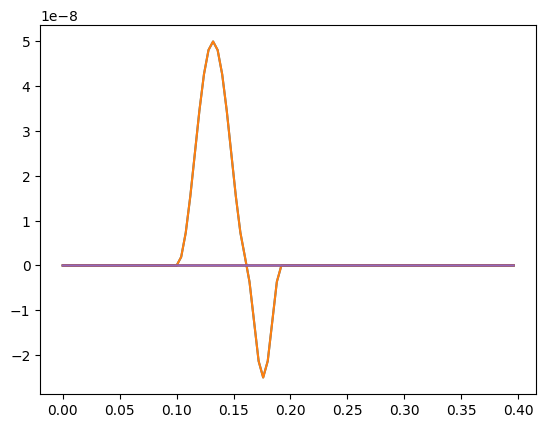

In [130]:
import matplotlib.pyplot as plt

for i in [537, 539, 101,102,103]:
    plt.plot(activity.times, X[i,:])

plt.show()

In [56]:
# Find the maximum delay to precompute delay-weight matrices
max_delay = np.max(D_int)

# Precompute delay-specific weight matrices
if not isinstance(W, csr_matrix):
    W = csr_matrix(W)
delay_weights = build_delay_weight_matrices(W, D_int, max_delay)

array([537, 539, 557, 579, 606, 633, 671, 673, 695, 698, 719, 721, 832])

In [ ]:
test = delay_weights[1].todense()
mm.viz.plot_connectome(test)

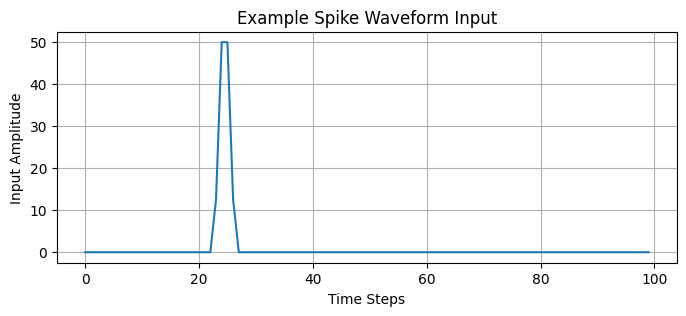

In [143]:
import numpy as np
import matplotlib.pyplot as plt
import pywt

# --- 1. Define Connectome (Dummy Data) ---
num_nodes = 50
adjacency_matrix = np.random.rand(num_nodes, num_nodes) < 0.05 # 5 % connection density
np.fill_diagonal(adjacency_matrix, 0) # no self-loops

# Delays matrix
delays_matrix = np.zeros((num_nodes, num_nodes))
connected_indices = np.where(adjacency_matrix > 0)
delays_matrix[connected_indices] = np.random.uniform(1, 10, size=len(connected_indices[0]))

# Idendtify source node(s)
source_nodes = [0]       # Let's say 0 is the source

# --- 2. Define Spike Waveform (Dummy Data) ---
# Let's create a Ricker wavelet
spike_duration = 100     # time steps
spike_amplitude = 50.0

# The 'a' parameter for ricker wavelet controls width. Larger 'a' means wider wavelet
spike_waveform = np.zeros(spike_duration)
w = pywt.ContinuousWavelet("mexh")
a, t = w.wavefun(length = 30)
spike_waveform[10:40] = spike_amplitude * a

# ensure it starts at 0 and goes up
spike_waveform = np.maximum(0, spike_waveform)

# normalize so max amplitude is spike_amplitude
if np.max(spike_waveform) > 0:
    spike_waveform = spike_waveform / np.max(spike_waveform) * spike_amplitude

plt.figure(figsize=(8,3))
plt.plot(spike_waveform)
plt.title("Example Spike Waveform Input")
plt.xlabel("Time Steps")
plt.ylabel("Input Amplitude")
plt.grid(True)
plt.show()

In [145]:
# --- 3. Coupled Oscillator Model Parameters ---
dt = 0.1
T_sim = 200
num_steps = int(T_sim / dt)

omega_intrinsic = np.full(num_nodes, 0.1)
coupling_strength = 0.5

# Threshold and Refractory Period
activation_threshold = 1.0
reset_value = 0.0
refractory_period_steps = int(5 / dt)

# Store activity history for delayed coupling
# We need to store enough history to cover the maximum delay
max_delay_steps = int(np.max(delays_matrix) / dt) + 1 if np.max(delays_matrix) > 0 else 1
activity_history = np.zeros((max_delay_steps, num_nodes))

# Initialize oscillator states 
theta = np.zeros(num_nodes)

# To store the simulation results
activity_over_time = np.zeros((num_steps, num_nodes))
fired_events = [[] for _ in range(num_nodes)]

# Refractory timer for each node 
refractory_timers = np.zeros(num_nodes, dtype=int)

# --- 4. Simulation Loop
print(f"Starting simulation for {num_steps} steps...")

for t_step in range(num_steps):
    # Apply spike waveform at source nodes
    current_input_spike = np.zeros(num_nodes)
    if t_step < spike_duration:
        for source_node in source_nodes:
            current_input_spike[source_node] = spike_waveform[t_step]


    # Calculate net input from neighbors with delays
    delayed_input = np.zeros(num_nodes)
    for i in range(num_nodes):
        for j in connected_indices[1][connected_indices[0] == i]:
            delay_steps = int(delays_matrix[i, j] / dt)
            if delay_steps >= max_delay_steps:
                delay_steps = max_delay_steps -1    # clamp to max history length


            # Get the activity of node j from the past
            # activity_history[k, j] stores activity of node j at time (t_step)
            history_idx = (max_delay_steps - 1) - delay_steps
            if history_idx >= 0 and history_idx < max_delay_steps:
                delayed_j_activity = activity_history[history_idx, j]
                delayed_input[i] += coupling_strength * delayed_j_activity * adjacency_matrix[i, j]
            else:
                pass

    # Update oscillator states
    dtheta_dt = omega_intrinsic + current_input_spike + delayed_input

    # apply refractory period
    dtheta_dt[refractory_timers > 0] = 0

    theta += dtheta_dt * dt

    # Apply thresholding and reset
    for i in range(num_nodes):
        if refractory_timers[i] > 0:
            refractory_timers[i] -= 1
        else:
            if theta[i] >= activation_threshold:
                fired_events[i].append(t_step * dt)
                theta[i] = reset_value
                refractory_timers[i] = refractory_period_steps 

    # store current activity and update history
    activity_over_time[t_step, :] = theta

    # shift history
    activity_history = np.roll(activity_history, -1, axis=0)
    activity_history[-1, :] = theta

print("Simulation complete")

Starting simulation for 2000 steps...
Simulation complete


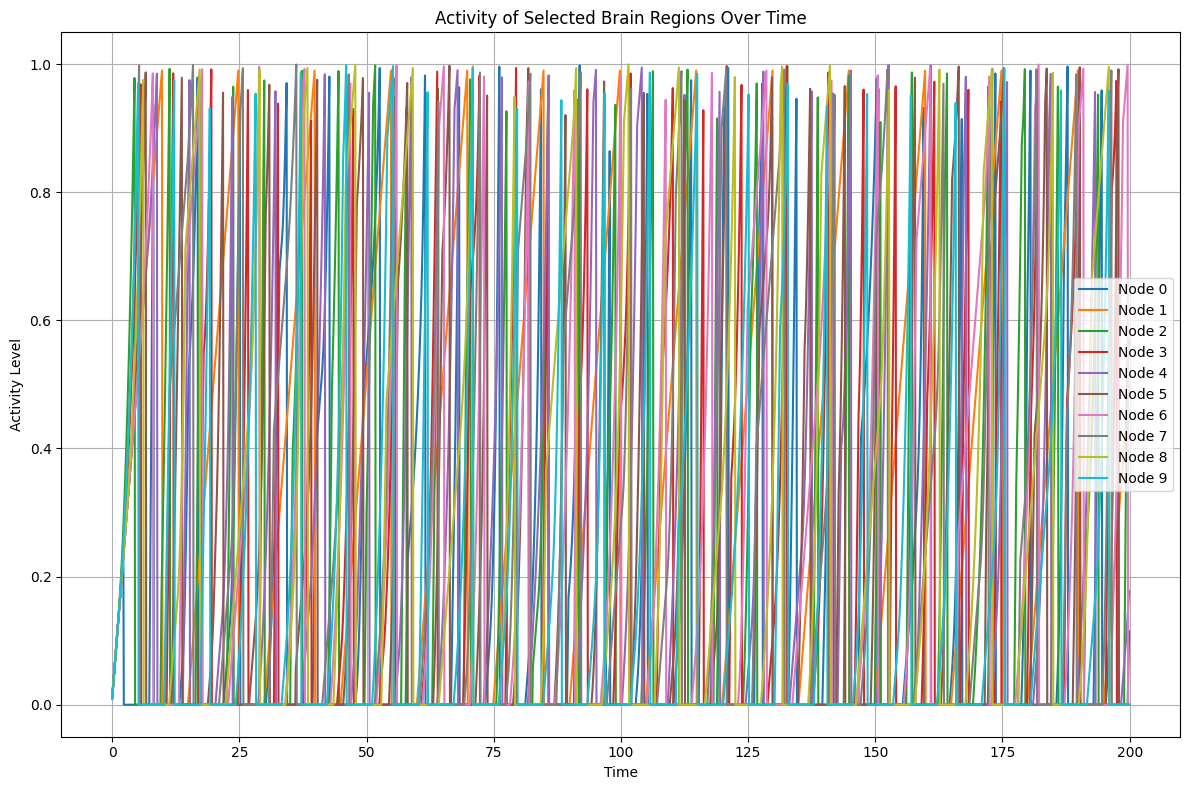

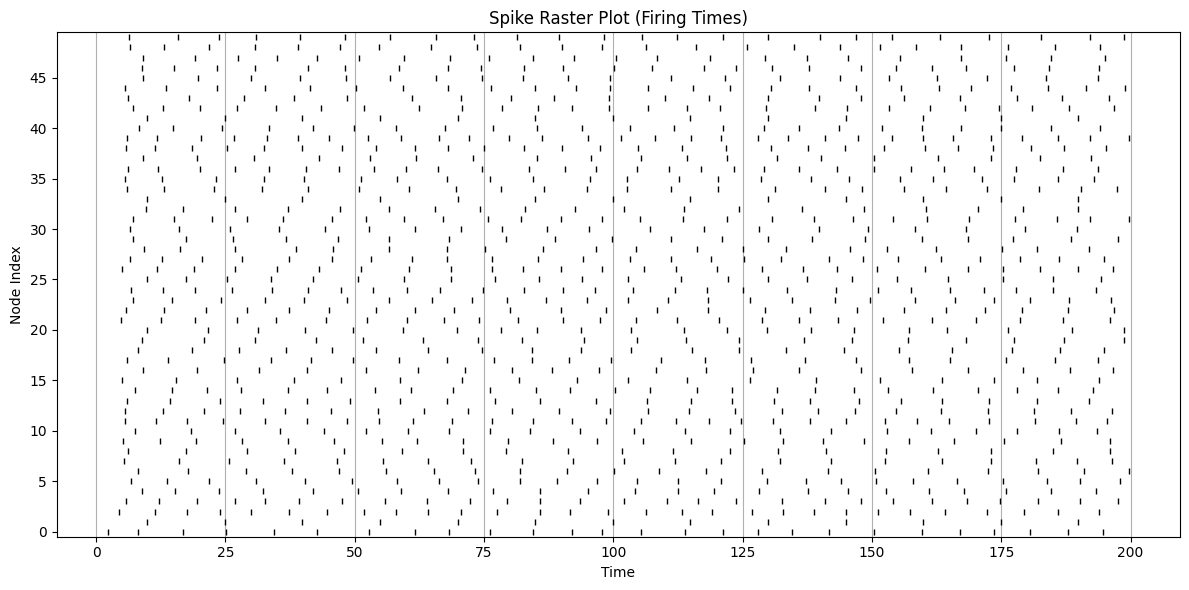

In [146]:
# --- 5. Visualization ---
plt.figure(figsize=(12, 8))

# Plot activity of a few representative nodes
num_plots = min(10, num_nodes)
for i in range(num_plots):
    plt.plot(np.arange(num_steps) * dt, activity_over_time[:, i], label=f'Node {i}')

plt.title('Activity of Selected Brain Regions Over Time')
plt.xlabel('Time')
plt.ylabel('Activity Level')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot spike raster plot
plt.figure(figsize=(12, 6))
for i in range(num_nodes):
    for t_fire in fired_events[i]:
        plt.plot(t_fire, i, '|', color='black', markersize=5) # Mark firing events

plt.title('Spike Raster Plot (Firing Times)')
plt.xlabel('Time')
plt.ylabel('Node Index')
plt.ylim(-0.5, num_nodes - 0.5)
plt.yticks(np.arange(0, num_nodes, 5)) # Adjust y-ticks based on num_nodes
plt.grid(True, axis='x')
plt.tight_layout()
plt.show()


In [1]:
# Python program to implement Runge Kutta method
# A sample differential equation "dy/dx = (x-y)/2"

def dydx(x,y):
    return ((x-y)/2)

# Finds value of y for a given x using step size h and initial value y0 at x0
def rungeKutta(x0, y0, x, h):
    # Count number of iterations using step size or step height h
    n = (int)((x-x0/h))

    # Iterate for number of iterations
    y = y0 
    for i in range(1, n+1):
        # Apply Runge Kutta Formulas to find next value of y
        k1 = h * dydx(x0, y)
        k2 = h * dydx(x0 + 0.5 * h, y + 0.5 * k1)
        k3 = h * dydx(x0 + 0.5 * h, y + 0.5 * k2)
        k4 = h * dydx(x0 + h, y + k3)

        # Update next value of y
        y = y + (1.0 / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

        # update next value value of x
        x0 = x0 + h 

    return y 

# Driver method
x0 = 0
y  = 1
x  = 2
h  = 0.2
print("The value of y at x is:", rungeKutta(x0, y, x, h))


The value of y at x is: 0.85619270421875


In [ ]:
from neurolib.models.aln import ALNModel

# Create the model
aln = ALNModel()

# Each model comes with